In [ ]:
Здесь у нас просто графики для давлений для подопытных

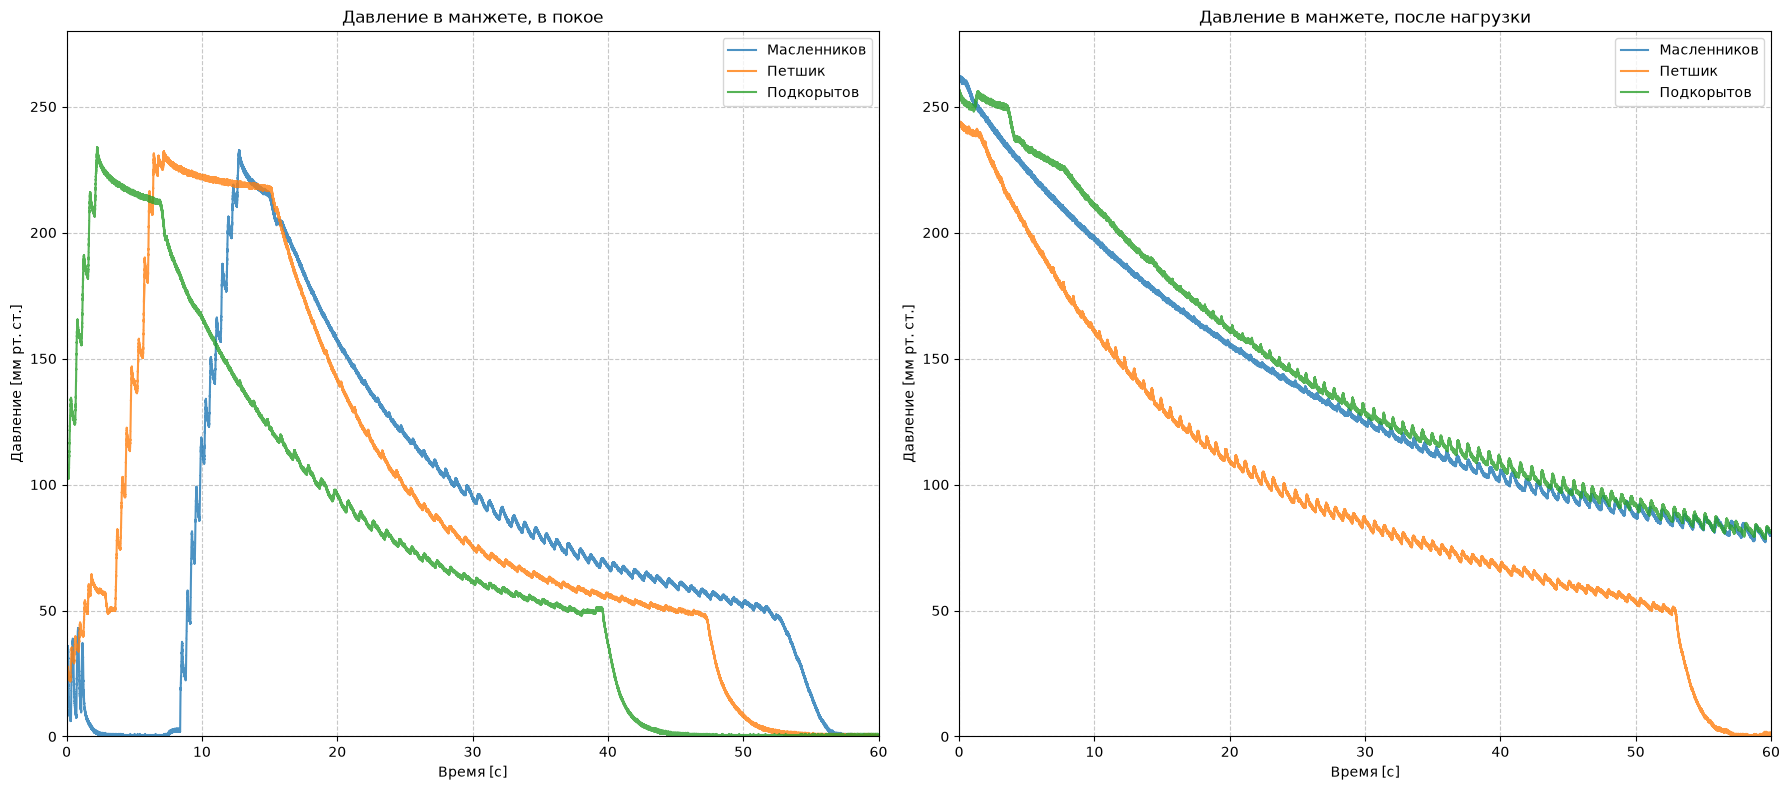

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import os

data_folder = '../5.3. Resting and post-exercise blood pressure'
files = ['rest_Mas.csv', 'rest_Pet.csv', 'rest_Pod.csv', 'fitness_Mas.csv', 'fitness_Pet.csv', 'fitness_Pod.csv']

names_map = {
    'Mas': 'Масленников',
    'Pet': 'Петшик',
    'Pod': 'Подкорытов'
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))

for f in files:
    filepath = os.path.join(data_folder, f)
    
    if not os.path.exists(filepath):
        continue
        
    df = pd.read_csv(filepath)
    t = df.iloc[:, 0].values
    p = df.iloc[:, 1].values

    code = f.split('_')[1].split('.')[0]
    label_name = names_map.get(code, f)

    if 'rest' in f:
        ax1.plot(t, p, label=label_name, alpha=0.8)
    elif 'fitness' in f:
        ax2.plot(t, p, label=label_name, alpha=0.8)

ax1.set_title('Давление в манжете, в покое')
ax1.set_xlabel('Время [с]')
ax1.set_ylabel('Давление [мм рт. ст.]')
ax1.set_xlim(0, 60)
ax1.set_ylim(0, 280)
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.set_title('Давление в манжете, после нагрузки')
ax2.set_xlabel('Время [с]')
ax2.set_ylabel('Давление [мм рт. ст.]')
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 280)
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('pressure_plots.png', bbox_inches='tight')
plt.show()


In [ ]:
Калибровка датчика

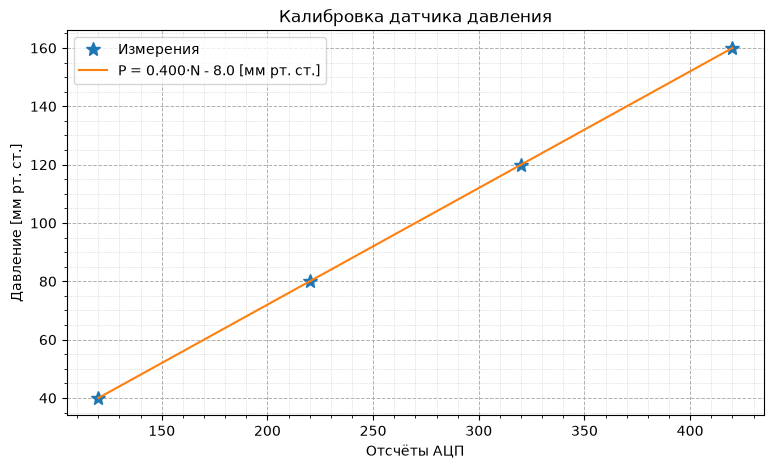

In [2]:
import matplotlib.pyplot as plt
import numpy as np


N = np.array([120, 220, 320, 420])  
P = np.array([40, 80, 120, 160])   


coeffs = np.polyfit(N, P, 1)
k = coeffs[0]
b = coeffs[1]


sign = "+" if b >= 0 else "-"
eq_text = f"P = {k:.3f}·N {sign} {abs(b):.1f} [мм рт. ст.]"


plt.figure(figsize=(9, 5))


plt.plot(N, P, '*', color='#1f77b4', markersize=10, label='Измерения')
plt.plot(N, np.polyval(coeffs, N), '-', color='#ff7f0e', label=eq_text)


plt.title("Калибровка датчика давления")
plt.xlabel("Отсчёты АЦП")
plt.ylabel("Давление [мм рт. ст.]")


plt.grid(True, which='major', linestyle='--', linewidth=0.7)
plt.minorticks_on()
plt.grid(True, which='minor', linestyle=':', linewidth=0.5, alpha=0.7)

plt.legend(loc='upper left')

plt.show()

In [ ]:
Здесь у нас графики с систолическим и диастолсическим давлением

Масленников (спокойный): САД 118 (5-я волна), ДАД 74 (0.8 от максимума), пульс 74


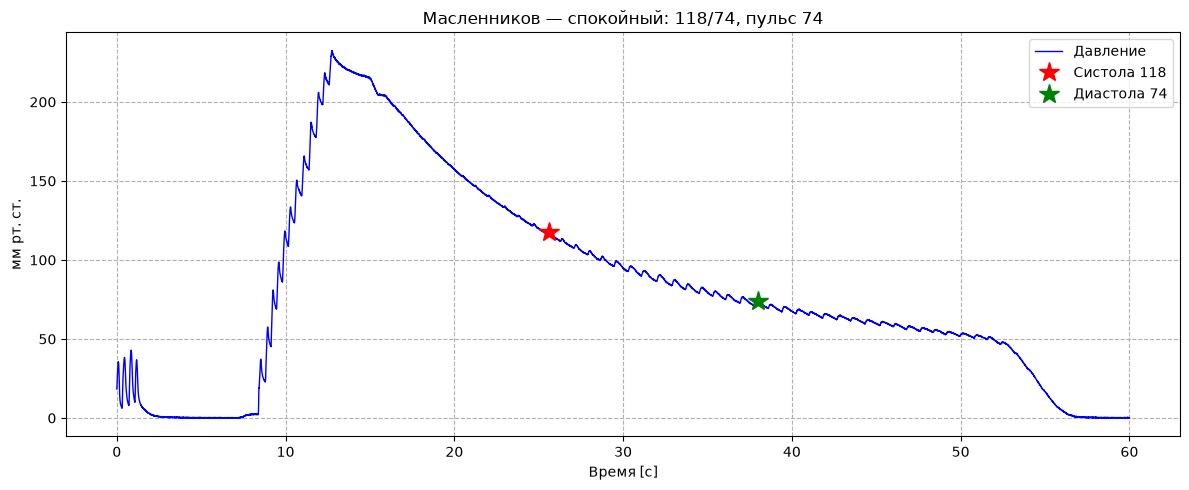

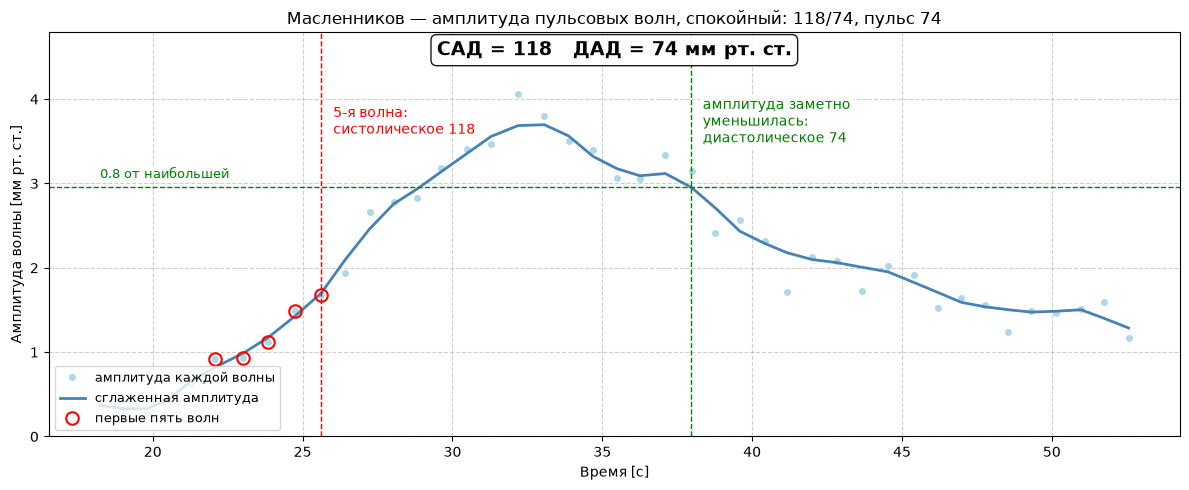

Масленников (после нагрузки): САД 136 (5-я волна), ДАД 94 (макс.амплитуда), пульс 75


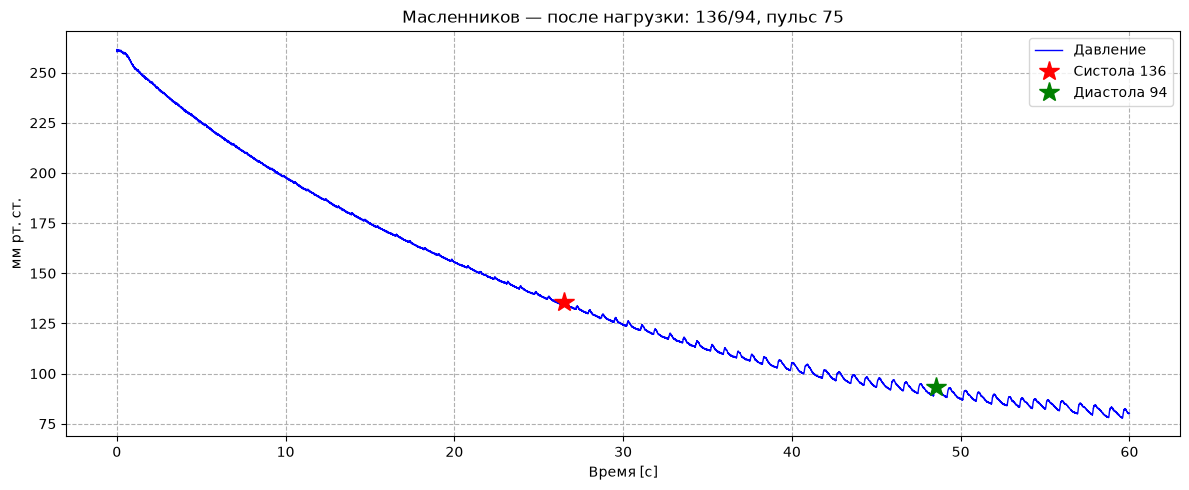

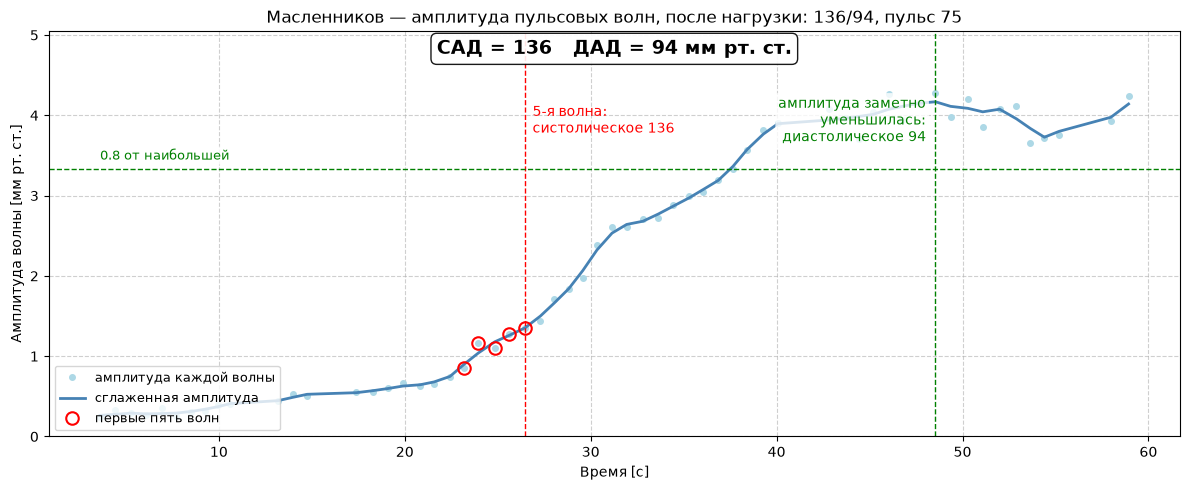

Петшик (спокойный): САД 130 (5-я волна), ДАД 72 (0.8 от максимума), пульс 59


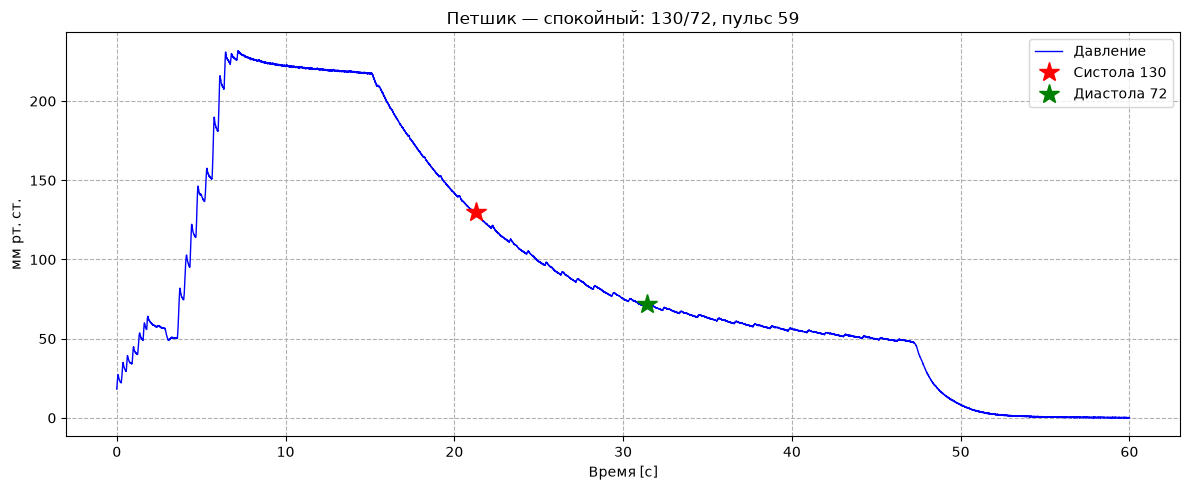

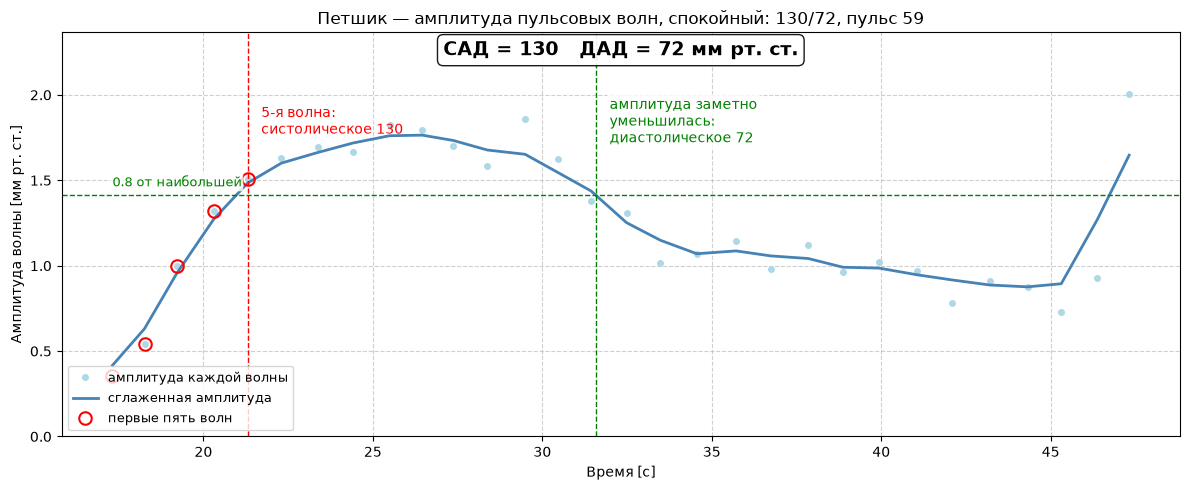

Петшик (после нагрузки): САД 145 (8-я волна), ДАД 93 (0.8 от максимума), пульс 84


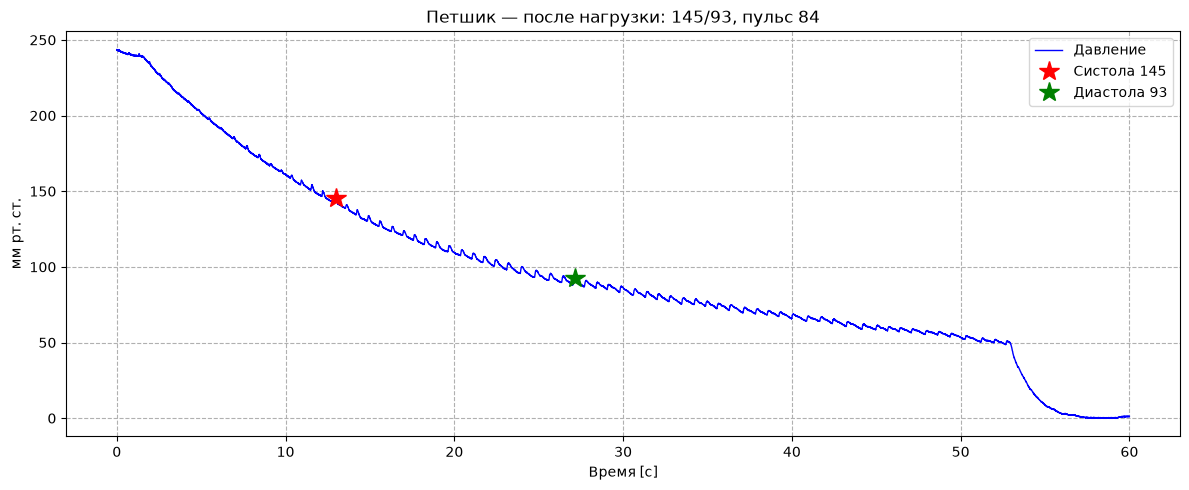

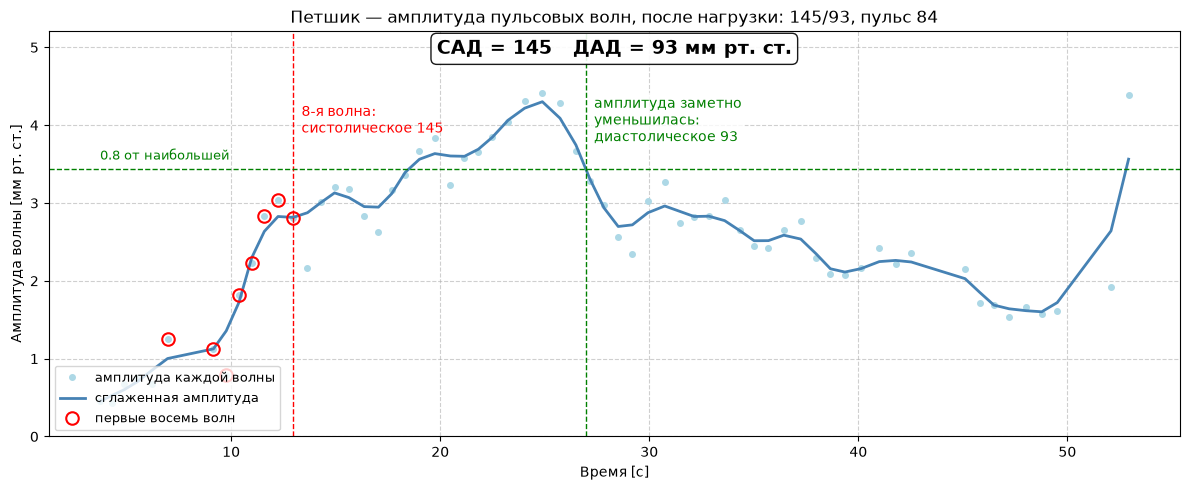

Подкорытов (спокойный): САД 119 (5-я волна), ДАД 83 (0.8 от максимума), пульс 61


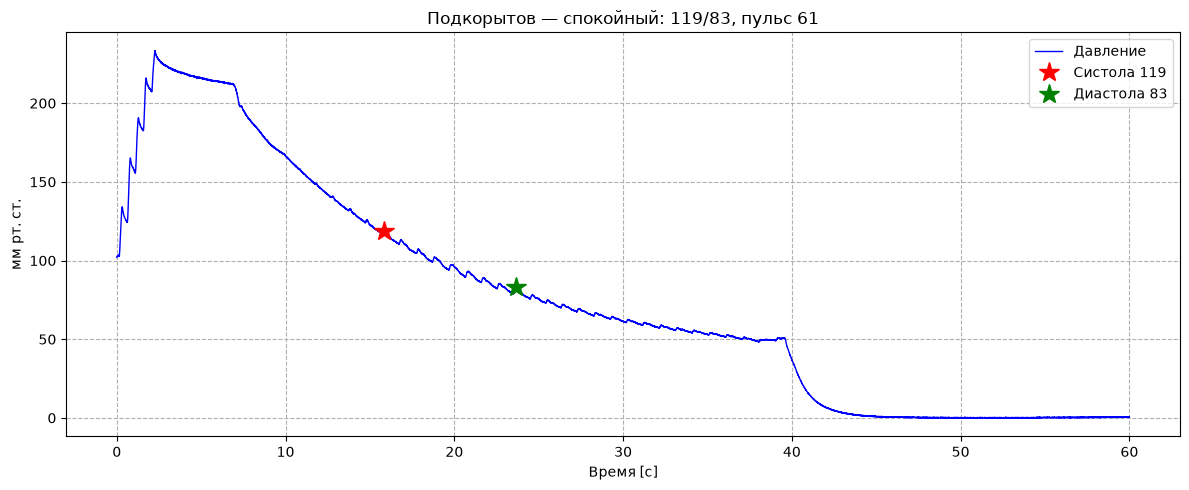

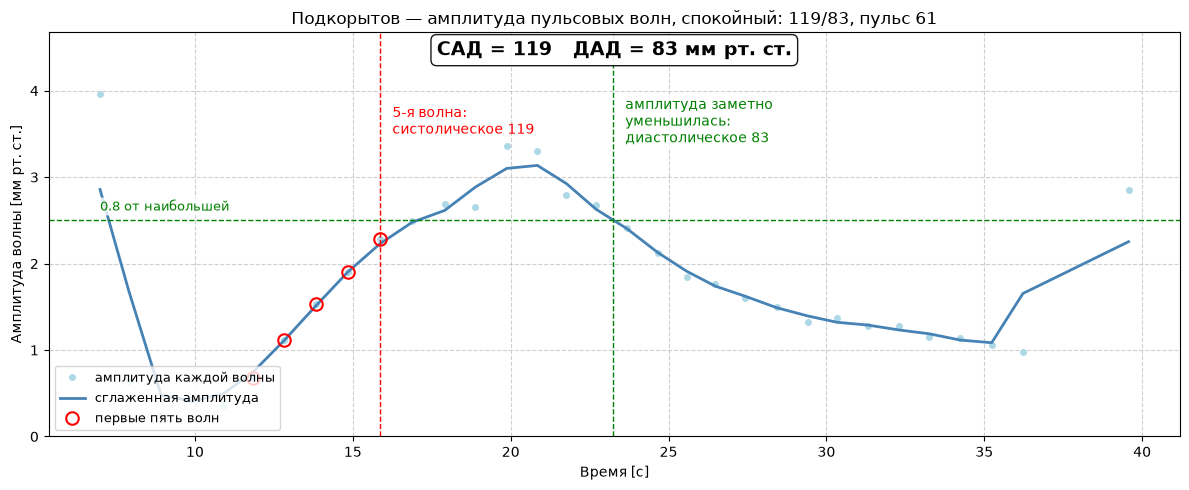

Подкорытов (после нагрузки): САД 159 (5-я волна), ДАД 96 (0.8 от максимума), пульс 84


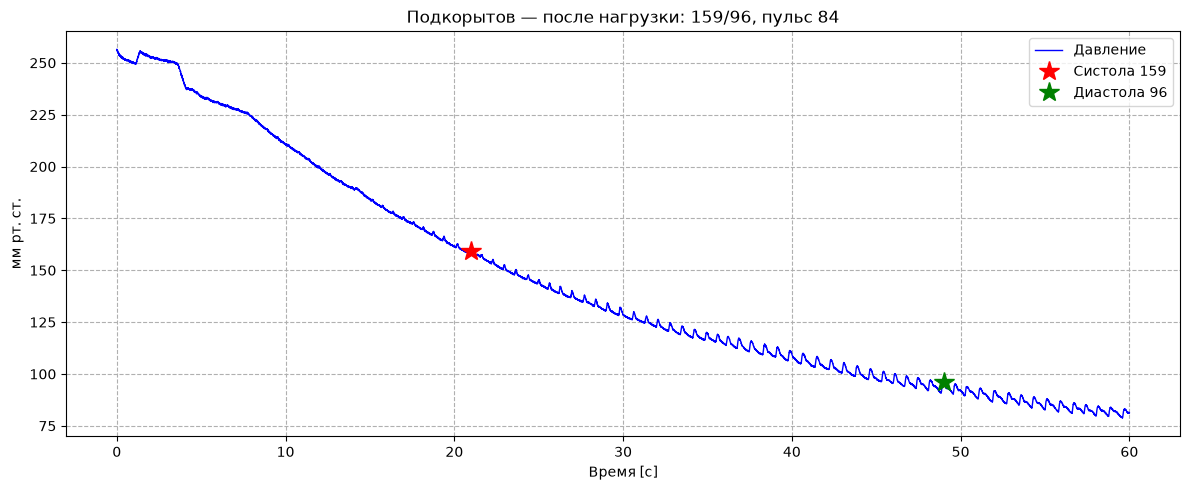

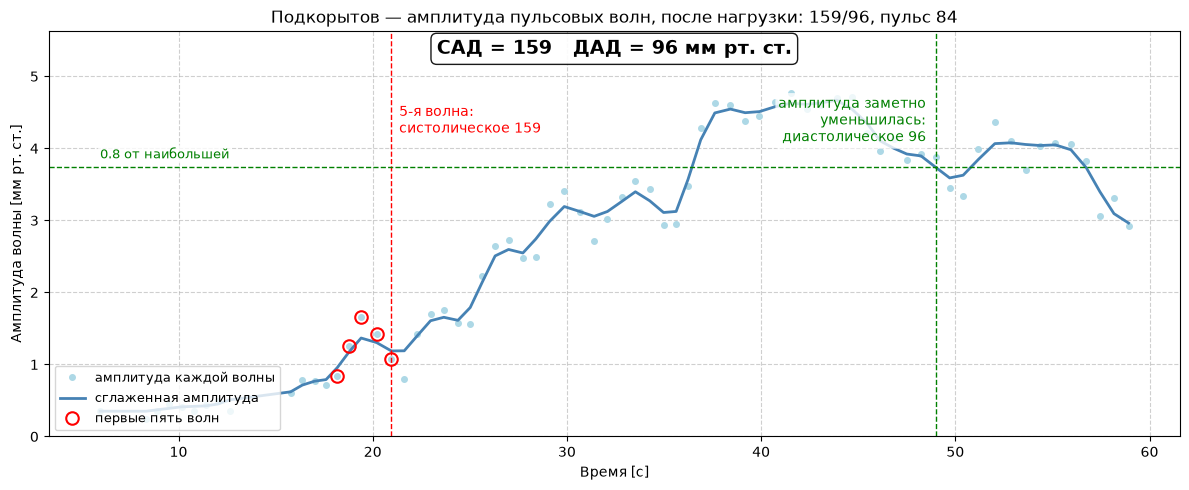


     subject           cond  sbp  dbp  map  pulse         dia_mode  valid
Масленников      спокойный  118   74   87     74 0.8 от максимума   True
Масленников после нагрузки  136   94   94     75   макс.амплитуда   True
     Петшик      спокойный  130   72   92     59 0.8 от максимума   True
     Петшик после нагрузки  145   93   97     84 0.8 от максимума   True
 Подкорытов      спокойный  119   83   93     61 0.8 от максимума   True
 Подкорытов после нагрузки  159   96  104     84 0.8 от максимума   True


In [41]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks
from scipy.ndimage import uniform_filter1d, median_filter

DATA_DIR = '.'
FILES = {
    'Масленников': {'rest': 'rest_Mas.csv', 'fitness': 'fitness_Mas.csv'},
    'Петшик': {'rest': 'rest_Pet.csv', 'fitness': 'fitness_Pet.csv'},
    'Подкорытов': {'rest': 'rest_Pod.csv', 'fitness': 'fitness_Pod.csv'},
}
COND_NAMES = {'rest': 'спокойный', 'fitness': 'после нагрузки'}
FS_NEW = 200
TREND_WIN = 1.5
BAND = (0.8, 4.0)
APPEAR_FRAC = 0.20
DIA_FRAC = 0.80
SYS_WAVE = 5
SYS_WAVE_OVERRIDE = {('Петшик', 'fitness'): 8}

def load(path):
    txt = open(path, encoding='utf-8', errors='ignore').read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:,0].to_numpy(float), df.iloc[:,1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p); t, p = t[ok], p[ok]
    o = np.argsort(t); t, p = t[o], p[o]; t = t - t[0]
    if p.max() < 10: p = 83.66*p - 11.33
    return t, p

def downsample(t, p, fs_new=FS_NEW):
    fs = 1.0/np.median(np.diff(t))
    k = max(1, int(round(fs/fs_new)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], fs/k

def detrend(p, fs):
    trend = uniform_filter1d(p, size=max(1, int(fs*TREND_WIN)), mode='nearest')
    return p - trend

def bandpass(p, fs, band=BAND):
    sos = butter(3, band, btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, p)

def deflation_bounds(p, fs):
    sm = uniform_filter1d(p, int(fs*0.5), mode='nearest')
    M = sm.max()
    plat = np.where(sm >= M-3)[0]
    i0 = plat[-1] if len(plat) else int(np.argmax(sm))
    after = np.where(sm[i0:] < M-6)[0]
    if len(after): i0 += after[0]
    below = np.where(sm[i0:] < 20)[0]
    i1 = i0 + below[0] if len(below) else len(p)-1
    return i0, i1, len(below) == 0, M

def envelope(td, pd_, osc, fs, M):
    peaks,_ = find_peaks(osc, distance=int(0.35*fs), prominence=0.2)
    win = int(0.30*fs)
    tb, pb, amp = [], [], []
    for pk in peaks:
        a, b = max(0,pk-win), min(len(osc),pk+win)
        if pk-a < 5 or b-pk < 5: continue
        base = 0.5*(osc[a:pk].min() + osc[pk:b].min())
        tb.append(td[pk]); pb.append(pd_[pk]); amp.append(osc[pk]-base)
    tb, pb, amp = map(np.array, (tb, pb, amp))
    if len(amp) < 10: return None
    m = (tb > td[0]+2.0) & (pb < M-15) & (pb > 40) & (tb < td[-1]-1.0)
    tb, pb, amp = tb[m], pb[m], amp[m]
    if len(amp) < 10: return None
    pulse_raw = 60/np.median(np.diff(tb))
    rr = np.diff(tb); med = np.median(rr)
    good = np.ones(len(tb), bool)
    good[1:] &= (rr > 0.75*med) & (rr < 1.25*med)
    good[:-1] &= (rr > 0.75*med) & (rr < 1.25*med)
    tb, pb, amp = tb[good], pb[good], amp[good]
    sm = uniform_filter1d(median_filter(amp, 3, mode='nearest'), 3, mode='nearest')
    return tb, pb, amp, sm, pulse_raw

def find_appearance(sm, appear):
    vis = sm >= appear
    for i in range(len(sm)-2):
        if vis[i] and vis[i+1] and vis[i+2]:
            return i
    hit = np.where(vis)[0]
    return int(hit[0]) if len(hit) else 0

def estimate_methodical(tb, pb, amp, sm, sys_wave=SYS_WAVE):
    im = int(np.argmax(sm)); amax = sm[im]
    appear = APPEAR_FRAC*amax
    i_app = find_appearance(sm, appear)
    i_sys = min(i_app + sys_wave - 1, len(pb)-1)
    sbp = pb[i_sys]; t_sys = tb[i_sys]
    thr_d = DIA_FRAC*amax
    fall = np.where(sm[im:] <= thr_d)[0]
    if len(fall):
        j = im + int(fall[0])
        w = (sm[j-1]-thr_d)/(sm[j-1]-sm[j]) if j > 0 and sm[j-1] != sm[j] else 0.0
        dbp = pb[j-1] + w*(pb[j]-pb[j-1]) if j > 0 else pb[j]
        t_dia = tb[j-1] + w*(tb[j]-tb[j-1]) if j > 0 else tb[j]
        mode = '0.8 от максимума'
    else:
        dbp = pb[im]; t_dia = tb[im]; mode = 'макс.амплитуда'
    return dict(sbp=sbp, dbp=dbp, t_sys=t_sys, t_dia=t_dia, i_app=i_app, i_sys=i_sys,
                amax=amax, im=im, mode=mode, warn=(i_app <= 1), map=pb[im], sys_wave=sys_wave)

def sanity(e, pulse):
    bad = []
    if e['sbp'] <= e['dbp']: bad.append('САД<=ДАД')
    if pulse is None or not (30 <= pulse <= 220): bad.append('пульс вне 30-220')
    if e['sbp'] > 250 or e['dbp'] > 150: bad.append('давление вне диапазона')
    return bad

def plot_pressure(name, cond_label, t, p, tb, pb, e, pulse):
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(t, p, 'b-', lw=1, label='Давление')
    i = int(np.argmin(abs(pb - e['sbp'])))
    ax.plot(tb[i], e['sbp'], 'r*', ms=15, label=f"Систола {e['sbp']:.0f}")
    j = int(np.argmin(abs(pb - e['dbp'])))
    ax.plot(tb[j], e['dbp'], 'g*', ms=15, label=f"Диастола {e['dbp']:.0f}")
    ax.set_title(f"{name} — {cond_label}: {e['sbp']:.0f}/{e['dbp']:.0f}, пульс {pulse:.0f}")
    ax.set_xlabel('Время [с]'); ax.set_ylabel('мм рт. ст.')
    ax.legend(); ax.grid(ls='--')
    plt.tight_layout(); plt.show()

def plot_methodical(name, cond_label, tb, pb, amp, sm, e, pulse):
    fig, ax = plt.subplots(figsize=(12, 5))
    ymax = max(amp.max(), sm.max())*1.18
    ax.plot(tb, amp, 'o', color='lightblue', ms=4, label='амплитуда каждой волны')
    ax.plot(tb, sm, '-', color='steelblue', lw=2, label='сглаженная амплитуда')
    
    sl = slice(e['i_app'], e['i_sys']+1)
    lbl_waves = 'первые восемь волн' if e['sys_wave'] == 8 else 'первые пять волн'
    ax.plot(tb[sl], amp[sl], 'o', mfc='none', mec='red', ms=9, mew=1.5, label=lbl_waves)
    
    # Красная линия САД и подпись
    ax.axvline(e['t_sys'], color='red', ls='--', lw=1)
    ax.text(e['t_sys']+0.4, ymax*0.82, f"{e['sys_wave']}-я волна:\nсистолическое {e['sbp']:.0f}", color='red', va='top', fontsize=10)
    
    # Зеленая линия ДАД и умное размещение подписи (влево, если мало места справа)
    ax.axvline(e['t_dia'], color='green', ls='--', lw=1)
    t_span = tb[-1] - tb[0]
    if (tb[-1] - e['t_dia']) < 0.22 * t_span:
        dia_x, dia_ha = e['t_dia'] - 0.5, 'right'
    else:
        dia_x, dia_ha = e['t_dia'] + 0.4, 'left'
        
    ax.text(dia_x, ymax*0.84, f"амплитуда заметно\nуменьшилась:\nдиастолическое {e['dbp']:.0f}",
            color='green', va='top', ha=dia_ha, fontsize=10,
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))
    
    # Горизонтальная линия 0.8 от наибольшей и подпись слева, чтобы не наезжала на график
    thr_y = DIA_FRAC * e['amax']
    ax.axhline(thr_y, color='green', ls='--', lw=1)
    ax.text(tb[0], thr_y + ymax*0.015, f'{DIA_FRAC} от наибольшей', color='green', ha='left', va='bottom', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.15', facecolor='white', alpha=0.8, edgecolor='none'))
    
    ax.text(0.5, 0.98, f"САД = {e['sbp']:.0f}   ДАД = {e['dbp']:.0f} мм рт. ст.",
            transform=ax.transAxes, ha='center', va='top', fontsize=14, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='black'))
    ax.set_ylim(0, ymax)
    ax.set_title(f'{name} — амплитуда пульсовых волн, {cond_label}: {e["sbp"]:.0f}/{e["dbp"]:.0f}, пульс {pulse:.0f}')
    ax.set_xlabel('Время [с]'); ax.set_ylabel('Амплитуда волны [мм рт. ст.]')
    ax.grid(True, ls='--', alpha=0.6); ax.legend(loc='lower left', fontsize=9)
    plt.tight_layout(); plt.show()

rows = []
for name, f in FILES.items():
    for cond in ('rest', 'fitness'):
        path = os.path.join(DATA_DIR, f[cond])
        if not os.path.exists(path): print('НЕТ ФАЙЛА:', path); continue
        t, p, fs = downsample(*load(path))
        i0, i1, truncated, M = deflation_bounds(p, fs)
        td, pd_ = t[i0:i1+1], p[i0:i1+1]
        osc = bandpass(detrend(pd_, fs), fs)
        env = envelope(td, pd_, osc, fs, M)
        if env is None: print(f'{name}: мало волн'); continue
        tb, pb, amp, sm, pulse_raw = env
        e = estimate_methodical(tb, pb, amp, sm, SYS_WAVE_OVERRIDE.get((name, cond), SYS_WAVE))
        pulse = pulse_raw
        bad = sanity(e, pulse)
        tag = '  [НЕВАЛИДНО: ' + ', '.join(bad) + ']' if bad else ''
        print(f"{name} ({COND_NAMES[cond]}): САД {e['sbp']:.0f} ({e['sys_wave']}-я волна), ДАД {e['dbp']:.0f} ({e['mode']}), пульс {pulse:.0f}{tag}")
        rows.append(dict(subject=name, cond=COND_NAMES[cond], sbp=round(e['sbp']),
                         dbp=round(e['dbp']), map=round(e['map']), pulse=round(pulse),
                         dia_mode=e['mode'], valid=not bad))
        plot_pressure(name, COND_NAMES[cond], t, p, tb, pb, e, pulse)
        plot_methodical(name, COND_NAMES[cond], tb, pb, amp, sm, e, pulse)
print('\n', pd.DataFrame(rows).to_string(index=False))


In [40]:
Здесь пульсации

SyntaxError: invalid syntax (4140795294.py, line 1)

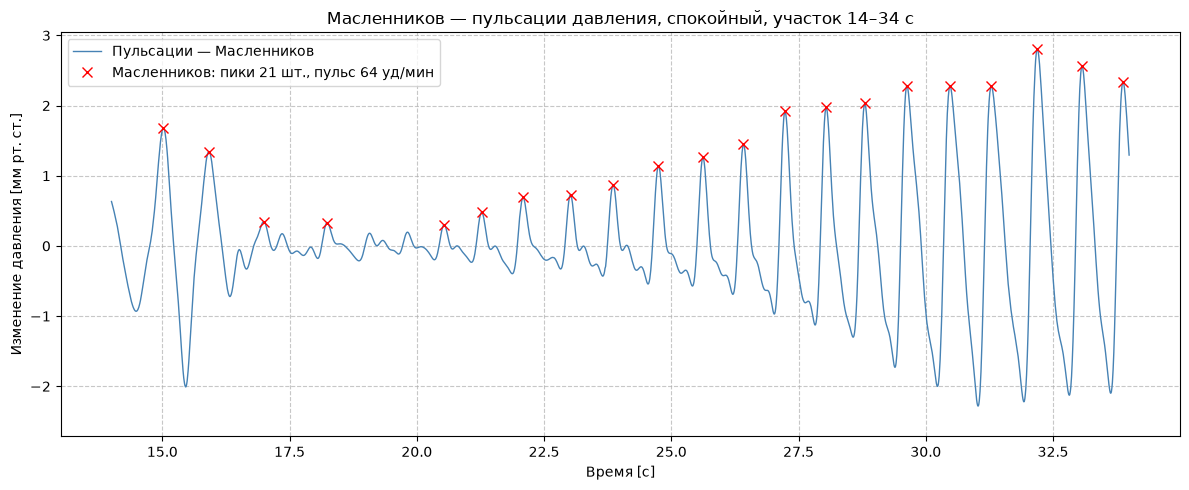

Масленников (спокойный): пики 21, пульс 64


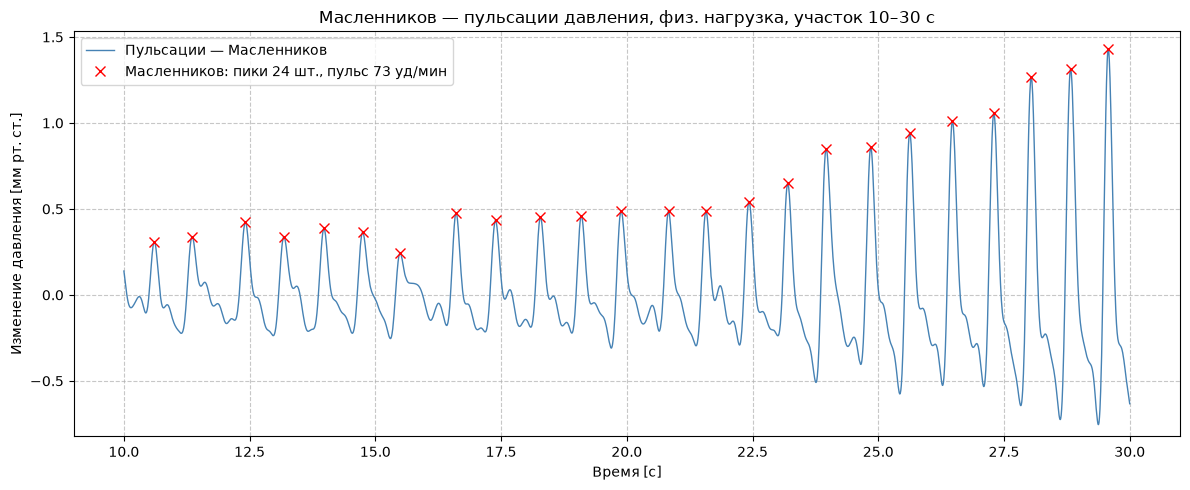

Масленников (физ. нагрузка): пики 24, пульс 73


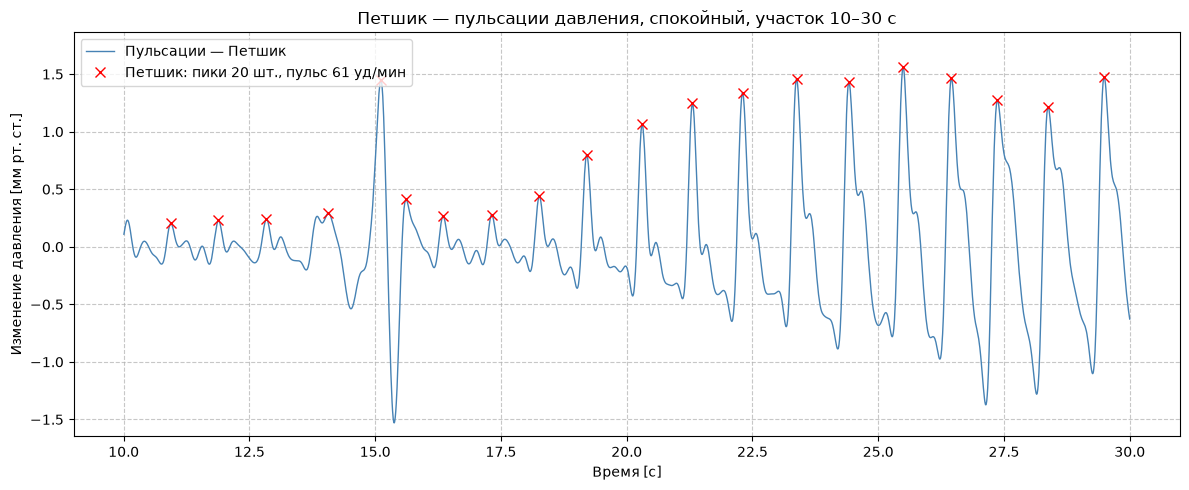

Петшик (спокойный): пики 20, пульс 61


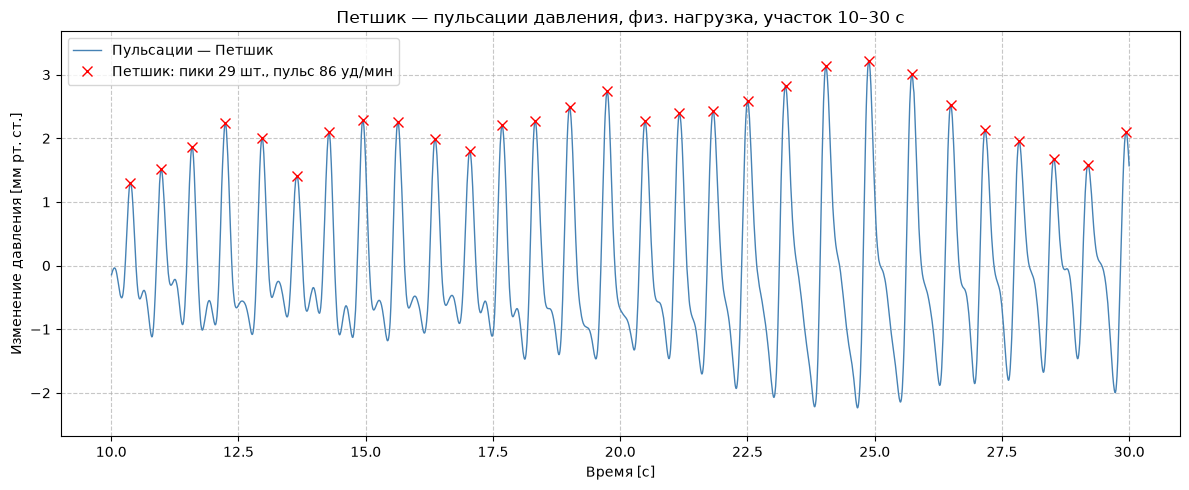

Петшик (физ. нагрузка): пики 29, пульс 86


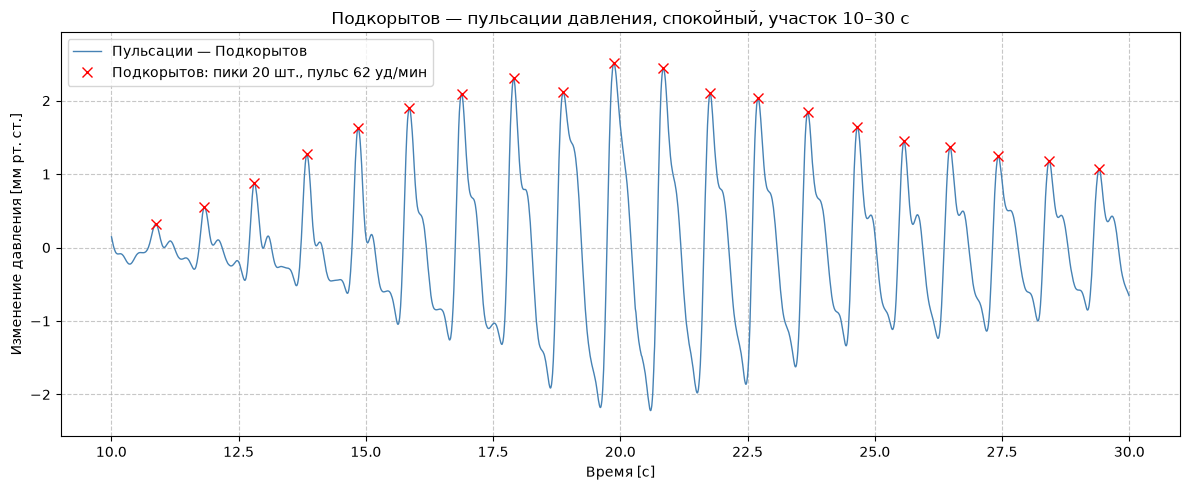

Подкорытов (спокойный): пики 20, пульс 62


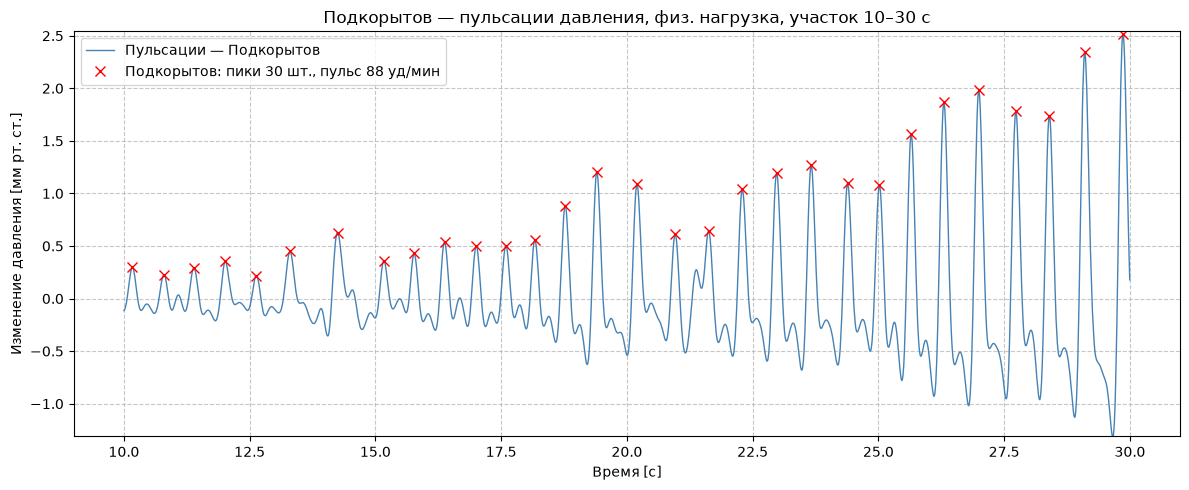

Подкорытов (физ. нагрузка): пики 30, пульс 88

     subject          cond  peaks  pulse  valid
Масленников     спокойный     21     64   True
Масленников физ. нагрузка     24     73   True
     Петшик     спокойный     20     61   True
     Петшик физ. нагрузка     29     86   True
 Подкорытов     спокойный     20     62   True
 Подкорытов физ. нагрузка     30     88   True


In [18]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks
from scipy.ndimage import uniform_filter1d

DATA_DIR = '.'
FILES = {
    'Масленников': {'rest': 'rest_Mas.csv', 'fitness': 'fitness_Mas.csv'},
    'Петшик': {'rest': 'rest_Pet.csv', 'fitness': 'fitness_Pet.csv'},
    'Подкорытов': {'rest': 'rest_Pod.csv', 'fitness': 'fitness_Pod.csv'},
}
WINDOW = (10.0, 30.0)
WINDOW_OVERRIDE = {('Масленников', 'rest'): (14.0, 34.0)}
FS_NEW = 200
TREND_WIN = 1.5
BAND = (0.8, 4.0)
OUTLIER_K = 5.0

def load(path):
    txt = open(path, encoding='utf-8', errors='ignore').read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:,0].to_numpy(float), df.iloc[:,1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p); t, p = t[ok], p[ok]
    o = np.argsort(t); t, p = t[o], p[o]; t = t - t[0]
    if p.max() < 10: p = 83.66*p - 11.33
    return t, p

def downsample(t, p, fs_new=FS_NEW):
    fs = 1.0/np.median(np.diff(t))
    k = max(1, int(round(fs/fs_new)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], fs/k

def detrend(p, fs):
    trend = uniform_filter1d(p, size=max(1, int(fs*TREND_WIN)), mode='nearest')
    return p - trend

def bandpass(p, fs, band=BAND):
    sos = butter(3, band, btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, p)

def plot_pulsations(name, cond, t, p, fs):
    w0, w1 = WINDOW_OVERRIDE.get((name, cond), WINDOW)
    osc = bandpass(detrend(p, fs), fs)
    m = (t >= w0) & (t <= w1)
    tw, ow = t[m], osc[m]
    
    # === ЗДЕСЬ УСЛОВИЕ ДЛЯ КОНКРЕТНОГО ФАЙЛА ===
    if name == 'Масленников' and cond == 'rest':
        # Золотая середина: порог 0.3, отсечка 20% от медианы
        peaks, _ = find_peaks(ow, distance=int(0.35*fs), prominence=0.3)
        if len(peaks):
            scale = np.median(ow[peaks])
            peaks = peaks[(ow[peaks] <= OUTLIER_K*scale) & (ow[peaks] >= 0.2 * scale)]
    else:
        # Старый мягкий режим для ВСЕХ ОСТАЛЬНЫХ
        peaks, _ = find_peaks(ow, distance=int(0.35*fs), prominence=0.15)
        if len(peaks):
            scale = np.median(ow[peaks])
            peaks = peaks[ow[peaks] <= OUTLIER_K*scale]
    # ============================================

    n = len(peaks)
    pulse = (n-1)*60/(tw[peaks[-1]]-tw[peaks[0]]) if n >= 2 else None
    bad = []
    if pulse is None or not (30 <= pulse <= 220): bad.append('пульс вне 30-220')
    if n < 5: bad.append('мало пиков')
    cond_title = 'физ. нагрузка' if cond == 'fitness' else 'спокойный'
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(tw, ow, color='steelblue', lw=1.0, label=f'Пульсации — {name}')
    lbl = f'{name}: пики {n} шт., пульс {pulse:.0f} уд/мин' if pulse else f'{name}: пики {n} шт.'
    ax.plot(tw[peaks], ow[peaks], 'x', color='red', markersize=7, label=lbl)
    lo, hi = np.percentile(ow, [1, 99])
    ax.set_ylim(lo*1.3, hi*1.3)
    ax.set_title(f'{name} — пульсации давления, {cond_title}, участок {w0:.0f}–{w1:.0f} с')
    ax.set_xlabel('Время [с]')
    ax.set_ylabel('Изменение давления [мм рт. ст.]')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend(loc='upper left')
    plt.tight_layout(); plt.show()
    return n, pulse, bad

rows = []
for name, f in FILES.items():
    for cond in ('rest', 'fitness'):
        path = os.path.join(DATA_DIR, f[cond])
        if not os.path.exists(path): print('НЕТ ФАЙЛА:', path); continue
        t, p, fs = downsample(*load(path))
        n, pulse, bad = plot_pulsations(name, cond, t, p, fs)
        cond_label = 'физ. нагрузка' if cond == 'fitness' else 'спокойный'
        tag = '  [НЕВАЛИДНО: ' + ', '.join(bad) + ']' if bad else ''
        if pulse:
            print(f'{name} ({cond_label}): пики {n}, пульс {pulse:.0f}{tag}')
        else:
            print(f'{name} ({cond_label}): пики {n}{tag}')
        rows.append(dict(subject=name, cond=cond_label, peaks=n,
                         pulse=round(pulse) if pulse else None, valid=not bad))
print('\n', pd.DataFrame(rows).to_string(index=False))

In [ ]:
Здесь высчитываем жесткость сосудов Петшика


==================== Петшик (Покой) ====================
Пульс: 62 уд/мин
SI (индекс жесткости): 6.78 м/с
C (растяжимость): 1.75 мл/мм рт.ст.


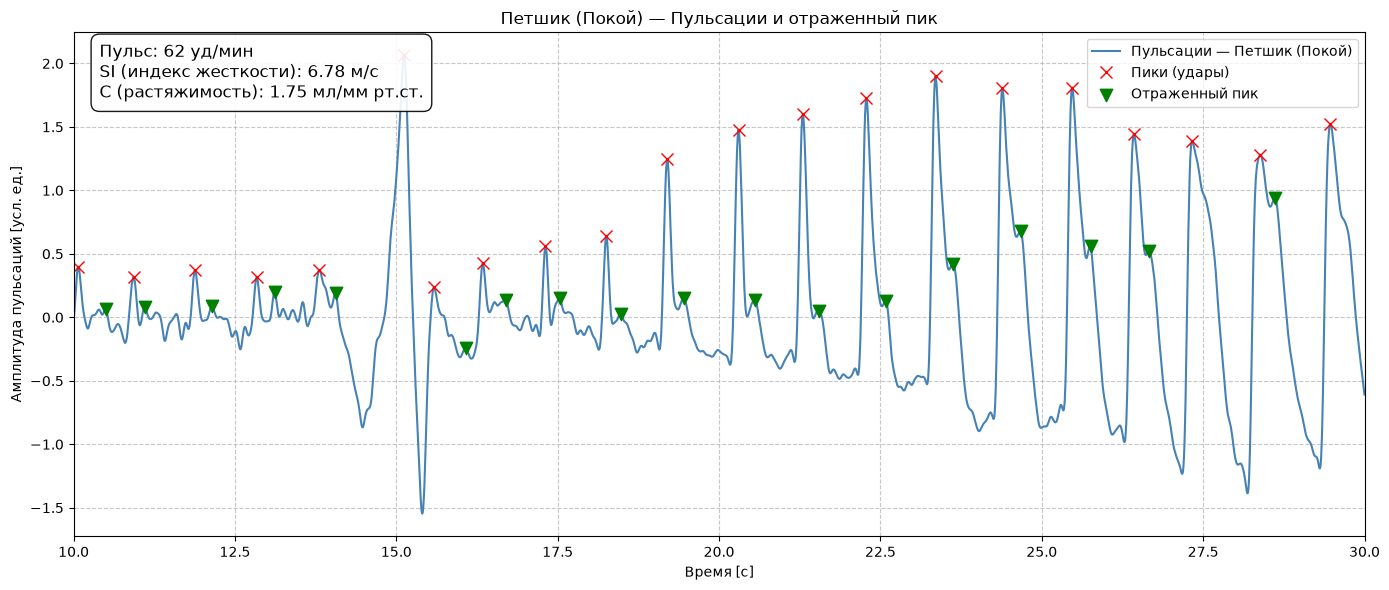


==================== Петшик (Нагрузка) ====================
Пульс: 86 уд/мин
SI (индекс жесткости): 3.67 м/с
C (растяжимость): 0.78 мл/мм рт.ст.


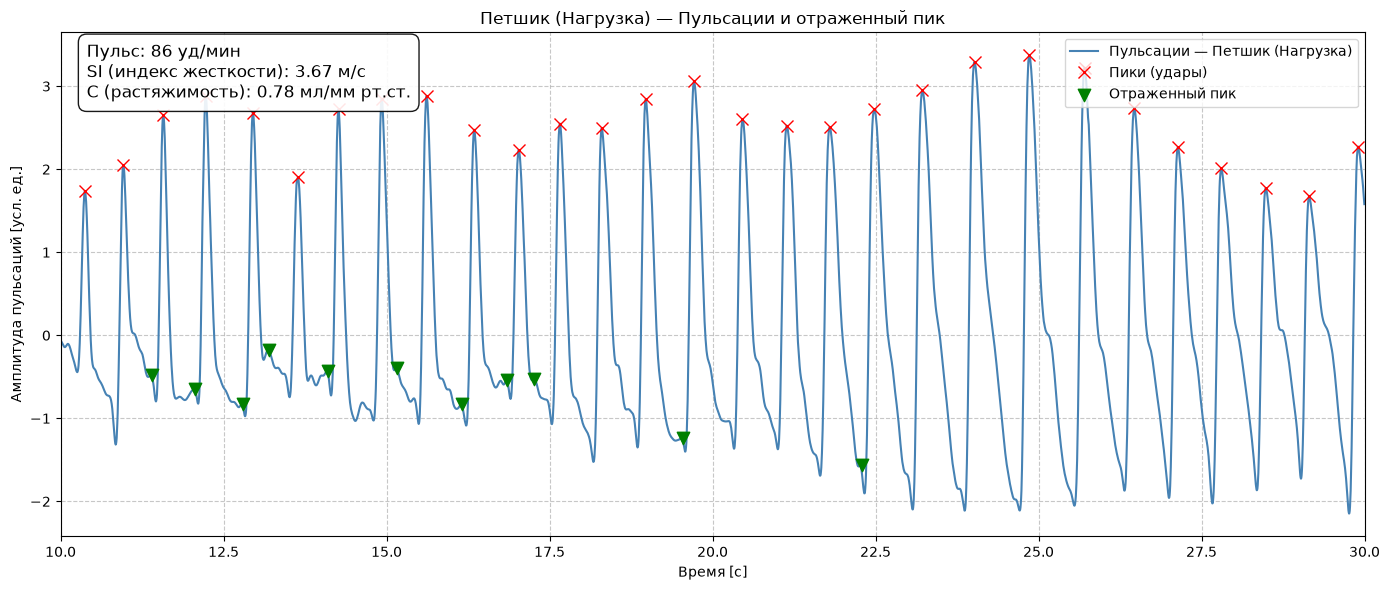

In [32]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks
from scipy.ndimage import uniform_filter1d

FILES = {
    'Петшик (Покой)': 'rest_Pet.csv',
    'Петшик (Нагрузка)': 'fitness_Pet.csv',
}
REST_KEY = 'Петшик (Покой)'

HEIGHT_M = 1.78
FS_NEW = 200
TREND_WIN = 1.5
BAND = (0.5, 8.0)
WINDOW = (10.0, 30.0)
SV_ML = 70.0      
PP_REST_REAL = 40.0  

def load_data(path):
    if not os.path.exists(path):
        return None, None, None
    with open(path, 'r', encoding='utf-8', errors='ignore') as f:
        txt = f.read()
    nums = np.array([float(x) for x in re.findall(r'-?\d+\.\d{4}', txt)])
    if nums.size >= 4 and nums.size % 2 == 0:
        t, p = nums[0::2], nums[1::2]
    else:
        df = pd.read_csv(path, header=None)
        t, p = df.iloc[:, 0].to_numpy(float), df.iloc[:, 1].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(p)
    t, p = t[ok], p[ok]
    t = t - t[0]
    if p.max() < 15:
        p = 83.66 * p - 11.33
    fs = 1.0 / np.median(np.diff(t))
    k = max(1, int(round(fs / FS_NEW)))
    p = uniform_filter1d(p, size=k, mode='nearest')
    return t[::k], p[::k], FS_NEW

def preprocess(p, fs):
    trend = uniform_filter1d(p, size=max(1, int(fs * TREND_WIN)), mode='nearest')
    p_detrend = p - trend
    sos = butter(3, BAND, btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, p_detrend)

def extract_metrics(path):
    t, p, fs = load_data(path)
    if t is None:
        return None

    p_filt = preprocess(p, fs)
    mask_win = (t >= WINDOW[0]) & (t <= WINDOW[1])
    tw, ow = t[mask_win], p_filt[mask_win]

    peaks, _ = find_peaks(ow, distance=int(0.35 * fs), prominence=0.3)
    n_peaks = len(peaks)
    pulse = (n_peaks - 1) * 60 / (tw[peaks[-1]] - tw[peaks[0]]) if n_peaks >= 2 else 0

    dt_values = []
    pp_values = []
    d_points = []

    for i in range(len(peaks) - 1):
        pk = peaks[i]
        next_pk = peaks[i + 1]
        cycle = ow[pk:next_pk]
        mn_idx = np.argmin(cycle)

        if mn_idx < 10:
            continue

        t_seg = np.arange(mn_idx) / fs
        p_seg = cycle[:mn_idx]

        pp = cycle[0] - cycle[mn_idx]
        if pp > 0:
            pp_values.append(pp)

        d_peaks, _ = find_peaks(p_seg, distance=int(0.05 * fs), prominence=0.01)
        if len(d_peaks) > 0:
            valid_d = d_peaks[d_peaks > int(0.05 * fs)]
            if len(valid_d) > 0:
                highest_d = valid_d[np.argmax(p_seg[valid_d])]
                dt = t_seg[highest_d]
                dt_values.append(dt)
                d_points.append((tw[pk] + dt, ow[pk + highest_d]))

    pp_raw = np.median(pp_values) if pp_values else 0
    SI = HEIGHT_M / np.median(dt_values) if dt_values else 0

    return {
        'tw': tw,
        'ow': ow,
        'peaks': peaks,
        'd_points': d_points,
        'pulse': pulse,
        'pp_raw': pp_raw,
        'SI': SI,
    }

results = {}
for name, path in FILES.items():
    res = extract_metrics(path)
    if res is None:
        print(f"Файл {path} не найден.")
    else:
        results[name] = res

if REST_KEY in results and results[REST_KEY]['pp_raw'] > 0:
    k_scale = PP_REST_REAL / results[REST_KEY]['pp_raw']
else:
    k_scale = 1.0

for name, data in results.items():
    print(f"\n{'='*20} {name} {'='*20}")

    pp_real = data['pp_raw'] * k_scale
    C_val = SV_ML / pp_real if pp_real > 0 else 0
    SI = data['SI']
    pulse = data['pulse']

    print(f"Пульс: {pulse:.0f} уд/мин")
    print(f"SI (индекс жесткости): {SI:.2f} м/с" if SI > 0 else "SI: не найден")
    print(f"C (растяжимость): {C_val:.2f} мл/мм рт.ст.")

    fig, ax = plt.subplots(figsize=(14, 6))
    tw, ow, peaks = data['tw'], data['ow'], data['peaks']

    ax.plot(tw, ow, color='steelblue', lw=1.5, label=f'Пульсации — {name}')
    ax.plot(tw[peaks], ow[peaks], 'x', color='red', markersize=8, label='Пики (удары)')

    if data['d_points']:
        dx, dy = zip(*data['d_points'])
        ax.scatter(dx, dy, color='green', s=80, marker='v', zorder=6, label='Отраженный пик')

    info_text = (
        f"Пульс: {pulse:.0f} уд/мин\n"
        f"SI (индекс жесткости): {SI:.2f} м/с\n"
        f"C (растяжимость): {C_val:.2f} мл/мм рт.ст."
    )

    ax.text(
        0.02, 0.98, info_text, transform=ax.transAxes, fontsize=12,
        verticalalignment='top', horizontalalignment='left',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.9, edgecolor='black')
    )

    ax.set_title(f'{name} — Пульсации и отраженный пик')
    ax.set_xlabel('Время [с]')
    ax.set_ylabel('Амплитуда пульсаций [усл. ед.]')
    ax.set_xlim(WINDOW[0], WINDOW[1])
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
